In [1]:
import agama, numpy, matplotlib, matplotlib.pyplot as plt 
import hunter2024mwmodel as h2024
import barframe

agama.setUnits(length=1, mass=1, velocity=1)

In [2]:
bar1=h2024.coleman2020(**h2024.coleman_components)
bar2=h2024.portail_component(**h2024.portail_bar_1)
bar3=h2024.portail_component(**h2024.portail_bar_2)    
pbar1   = agama.Potential(type='CylSpline', density=bar1,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20,)
pbar2   = agama.Potential(type='CylSpline', density=bar2,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20,)
pbar3   = agama.Potential(type='CylSpline', density=bar3,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20,)
pbar = pbar1+pbar2+pbar3

In [3]:
# the rest of the potetial 
psagA   = agama.Potential(**h2024.supermassiveblackhole)
pnsc    = agama.Potential(**h2024.nsc)
pnsd1   = agama.Potential(**h2024.NSD1,)
pnsd2   = agama.Potential(**h2024.NSD2)
pdisk1  = agama.Potential(**h2024.DISK1)
pdisk2  = agama.Potential(**h2024.DISK2)
pgdisk1 = agama.Potential(**h2024.GDISK1)
pgdisk2 = agama.Potential(**h2024.GDISK2)
phalo   = agama.Potential(**h2024.EINASTO)
pot_total=agama.Potential(pbar1,pbar2,pbar3,psagA,pnsc,pnsd1,pnsd2,pdisk1,pdisk2,pgdisk1,pgdisk2,phalo)

In [23]:
methods=list(dir(pbar))
methodss=[]
for x in methods:
    if x[0]!="_":
        methodss.append(x)
methodss

['Rcirc',
 'Rmax',
 'Rperiapo',
 'Tcirc',
 'density',
 'enclosedMass',
 'eval',
 'export',
 'force',
 'forceDeriv',
 'potential',
 'principalAxes',
 'projectedDensity',
 'projectedEval',
 'sample',
 'totalMass']

In [34]:
num_orbits = int(1e3)
ic,mass=pbar.sample(num_orbits,potential=pot_total)
print("%s" % ic[0:3,:])

[[ 3.05345459  0.13012646  0.03991643         nan         nan         nan]
 [-0.25653022  0.38904792  0.28152718         nan         nan         nan]
 [-0.45892186  0.22493001  0.42139067         nan         nan         nan]]


notice that there is no inversion for some sampling initial conditions for this bar structure. That's totally fine. It looks like I'll have to create the orbital family in a bit more intelligently. 

1. SOS and zero velocity curves? 
2. continue reading the tutorial? 

pick 1. 

In [35]:
omega = -37.5
x_l1 = barframe.xL1(pot_total, omega)
e_l1 = barframe.pot_eff(pot_total, omega, numpy.array([x_l1, 0.0, 0.0]))
e_0 = barframe.pot_eff(pot_total, omega, numpy.array([0.0, 0.0, 0.0]))

In [123]:
tolerence=1e-1
Ejs = -numpy.logspace(numpy.log10((1-5*tolerence)*numpy.abs(e_0)),
                    numpy.log10((1+tolerence)*numpy.abs(e_l1)),
                    num= 20)


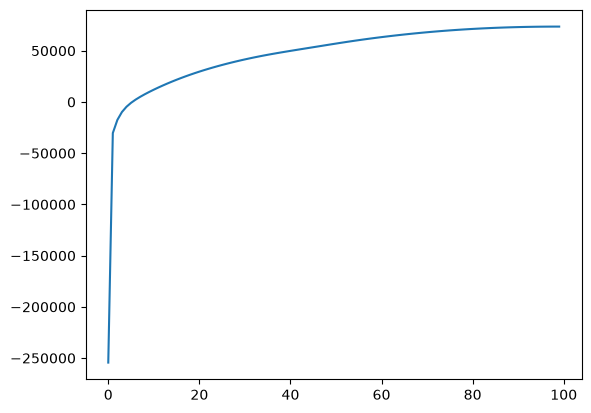

In [131]:
xs = numpy.linspace(0.00001,x_l1,100)
xyz = numpy.column_stack((xs,xs*0,xs*0))
plt.plot(barframe.pot_eff(pot_total,omega, xyz) - Ejs[0])

In [ ]:
# log sample Ej, so we are up higher 
nEjs = 10
NorbitsPerEj = 10
Norbits = NorbitsPerEj*nEjs
# for i in range(1,nEjs-1):
init_conds = barframe.sample_initial_conditions_allowed_within_bar(pot_total,omega,Ejs[0],norbits=NorbitsPerEj,)

array([[ 3.01536644e-01,  0.00000000e+00,  0.00000000e+00,
        -3.27650123e+01,  4.54677578e+01,  0.00000000e+00],
       [ 2.17188152e-01,  0.00000000e+00,  0.00000000e+00,
        -8.45864233e+01,  8.59487251e+01,  0.00000000e+00],
       [ 8.46720745e-03,  0.00000000e+00,  0.00000000e+00,
        -2.48340461e+02,  2.33758986e+02,  0.00000000e+00],
       [ 1.25002658e-01,  0.00000000e+00,  0.00000000e+00,
         1.28403743e+02,  1.37131748e+02,  0.00000000e+00],
       [-4.92580762e-02,  0.00000000e+00,  0.00000000e+00,
         2.39444367e+02,  1.06391153e+02,  0.00000000e+00],
       [ 2.15130318e-01,  0.00000000e+00,  0.00000000e+00,
        -3.94737131e+01,  1.15431824e+02,  0.00000000e+00],
       [ 5.00975784e-02,  0.00000000e+00,  0.00000000e+00,
         1.32225672e+02,  2.25032296e+02,  0.00000000e+00],
       [ 2.16301434e-01,  0.00000000e+00,  0.00000000e+00,
         1.05061565e+02,  6.04186343e+01,  0.00000000e+00],
       [-2.34751551e-01,  0.00000000e+00,  0.000